<a href="https://colab.research.google.com/github/syhn53/MNIST_FGSM/blob/main/MNIST_FGSM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# ==========================================
# 1. 라이브러리 불러오기 및 실험 환경 설정
# ==========================================

import torch
import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt
import random
import os

from torch.utils.data import Subset

# 랜덤 시드 설정
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# GPU 또는 CPU 설정
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch 버전:", torch.__version__)
print("Torchvision 버전:", torchvision.__version__)
print("사용 장치:", device)

if torch.cuda.is_available():
    print("GPU 이름:", torch.cuda.get_device_name(0))


PyTorch 버전: 2.11.0+cu130
Torchvision 버전: 0.26.0+cu130
사용 장치: cuda
GPU 이름: Tesla T4


In [ ]:

# ==========================================
# 2. Google Drive 연결 및 저장 경로 설정
# ==========================================

from google.colab import drive

drive.mount('/content/drive')

# 연구 폴더
BASE_DIR = "/content/drive/MyDrive/FGSM_Research"

# 모델 저장 폴더
CHECKPOINT_DIR = os.path.join(BASE_DIR, "checkpoints")

# 실험 결과 저장 폴더
RESULT_DIR = os.path.join(BASE_DIR, "results")

# 폴더가 없으면 생성
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

print("저장 폴더 생성 완료!")
print("모델 저장:", CHECKPOINT_DIR)
print("실험 결과 저장:", RESULT_DIR)


Mounted at /content/drive
저장 폴더 생성 완료!
모델 저장: /content/drive/MyDrive/FGSM_Research/checkpoints
실험 결과 저장: /content/drive/MyDrive/FGSM_Research/results


In [ ]:

# ==========================================
# 3. MNIST 데이터셋 불러오기
# ==========================================

# 이미지 픽셀값을 0~1 범위로 변환
transform = transforms.ToTensor()

# 학습 데이터 60,000장
train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# 테스트 데이터 10,000장
test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("학습 데이터 개수:", len(train_dataset))
print("테스트 데이터 개수:", len(test_dataset))


100%|██████████| 9.91M/9.91M [00:00<00:00, 20.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 497kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.53MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.9MB/s]

학습 데이터 개수: 60000
테스트 데이터 개수: 10000


In [ ]:

# ==========================================
# 4. D_private / D_independent 데이터 분할
# ==========================================

from sklearn.model_selection import train_test_split

# 전체 학습 데이터의 정답 레이블
labels = np.array(train_dataset.targets)

# 전체 데이터 인덱스
all_indices = np.arange(len(train_dataset))

# 숫자별 비율을 유지하면서 50:50 분할
private_indices, independent_indices = train_test_split(
    all_indices,
    test_size=0.5,
    random_state=SEED,
    stratify=labels
)

# Subset 데이터셋 생성
D_private = Subset(train_dataset, private_indices)
D_independent = Subset(train_dataset, independent_indices)

print("D_private:", len(D_private))
print("D_independent:", len(D_independent))
print("Test:", len(test_dataset))

# 데이터 중복 여부 확인
print(
    "중복 데이터 개수:",
    len(set(private_indices) & set(independent_indices))
)


D_private: 30000
D_independent: 30000
Test: 10000
중복 데이터 개수: 0


/tmp/ipykernel_1609/1186026984.py:8: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  labels = np.array(train_dataset.targets)


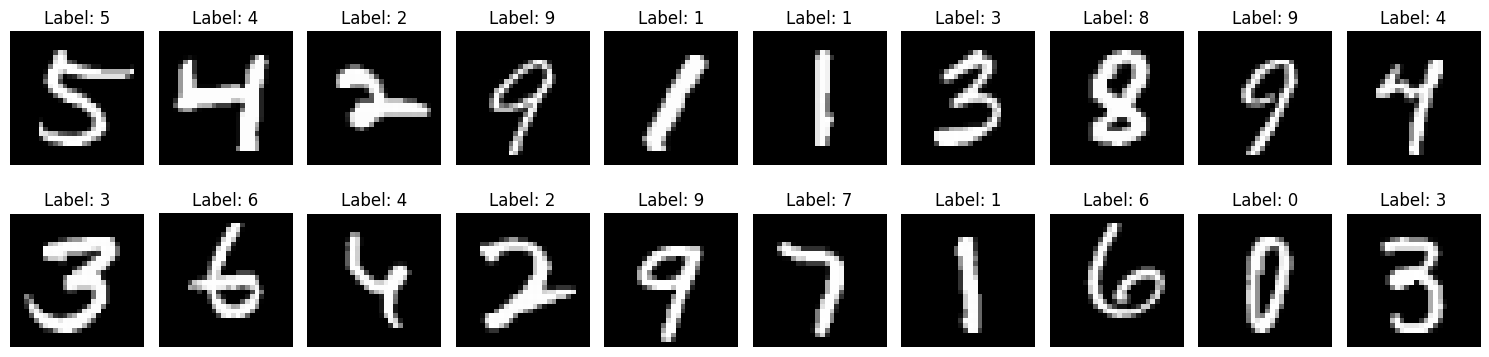

In [ ]:

# ==========================================
# 5. MNIST 이미지 시각화
# ==========================================

fig, axes = plt.subplots(2, 10, figsize=(15, 4))

# 첫 번째 줄: D_private
for i in range(10):
    image, label = D_private[i]

    axes[0, i].imshow(image.squeeze(), cmap="gray")
    axes[0, i].set_title(f"Label: {label}")
    axes[0, i].axis("off")

# 두 번째 줄: D_independent
for i in range(10):
    image, label = D_independent[i]

    axes[1, i].imshow(image.squeeze(), cmap="gray")
    axes[1, i].set_title(f"Label: {label}")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Private")
axes[1, 0].set_ylabel("Independent")

plt.tight_layout()
plt.show()


In [ ]:

# ==========================================
# 6. CNN 모델 정의
# ==========================================

import torch.nn as nn
import torch.nn.functional as F

class CNN(nn.Module):

    def __init__(self):
        super(CNN, self).__init__()

        # 첫 번째 합성곱층
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=32,
            kernel_size=3
        )

        # 두 번째 합성곱층
        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3
        )

        # 완전연결층
        self.fc1 = nn.Linear(64 * 5 * 5, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        # 첫 번째 합성곱 + ReLU + Pooling
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(x, 2)

        # 두 번째 합성곱 + ReLU + Pooling
        x = F.relu(self.conv2(x))
        x = F.max_pool2d(x, 2)

        # Flatten
        x = torch.flatten(x, 1)

        # 완전연결층
        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x


# 모델 생성
model = CNN().to(device)

print(model)


CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=1600, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [ ]:

# ==========================================
# 7. CNN 입력 및 출력 크기 확인
# ==========================================

dummy_input = torch.randn(1, 1, 28, 28).to(device)

with torch.no_grad():
    output = model(dummy_input)

print("입력 크기:", dummy_input.shape)
print("출력 크기:", output.shape)


입력 크기: torch.Size([1, 1, 28, 28])
출력 크기: torch.Size([1, 10])


In [ ]:

# ==========================================
# 8. DataLoader 생성
# ==========================================

from torch.utils.data import DataLoader

BATCH_SIZE = 128

# Model A와 B의 학습 데이터
private_loader = DataLoader(
    D_private,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# Model C의 학습 데이터
independent_loader = DataLoader(
    D_independent,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# 테스트 데이터
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("A/B 학습 배치 수:", len(private_loader))
print("C 학습 배치 수:", len(independent_loader))
print("테스트 배치 수:", len(test_loader))


A/B 학습 배치 수: 235
C 학습 배치 수: 235
테스트 배치 수: 79


In [ ]:

# ==========================================
# 9. 학습 및 평가 함수
# ==========================================

import torch.optim as optim

# 손실 함수
criterion = nn.CrossEntropyLoss()

# 모델 평가 함수
def evaluate(model, loader):

    model.eval()

    correct = 0
    total = 0
    total_loss = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    accuracy = 100 * correct / total
    avg_loss = total_loss / total

    return accuracy, avg_loss


# 모델 학습 함수
def train_model(
    model,
    train_loader,
    model_name,
    epochs=5,
    resume=False
):

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001
    )

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"{model_name}_latest.pth"
    )

    best_path = os.path.join(
        CHECKPOINT_DIR,
        f"{model_name}_best.pth"
    )

    start_epoch = 0
    best_accuracy = 0

    # 중단된 학습 이어하기
    if resume and os.path.exists(checkpoint_path):

        checkpoint = torch.load(
            checkpoint_path,
            map_location=device
        )

        model.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

        start_epoch = checkpoint["epoch"] + 1
        best_accuracy = checkpoint["best_accuracy"]

        print(f"{model_name}: {start_epoch} epoch부터 재개")

    # 학습 시작
    for epoch in range(start_epoch, epochs):

        model.train()

        running_loss = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            # 기울기 초기화
            optimizer.zero_grad()

            # 순전파
            outputs = model(images)

            # 손실 계산
            loss = criterion(outputs, labels)

            # 역전파
            loss.backward()

            # 가중치 업데이트
            optimizer.step()

            running_loss += loss.item()

        # 테스트 데이터 평가
        test_accuracy, test_loss = evaluate(
            model,
            test_loader
        )

        avg_train_loss = running_loss / len(train_loader)

        print(
            f"{model_name} | "
            f"Epoch [{epoch+1}/{epochs}] | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Test Loss: {test_loss:.4f} | "
            f"Test Accuracy: {test_accuracy:.2f}%"
        )

        # 최고 정확도 모델 저장
        if test_accuracy > best_accuracy:

            best_accuracy = test_accuracy

            torch.save(
                model.state_dict(),
                best_path
            )

        # 매 epoch 체크포인트 저장
        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_accuracy": best_accuracy
            },
            checkpoint_path
        )

    print(f"\n{model_name} 학습 완료!")
    print("최고 테스트 정확도:", best_accuracy)

    return model


In [ ]:

# ==========================================
# 10. A, B, C 모델 생성 및 학습
# ==========================================

EPOCHS = 5

# 서로 다른 초기 가중치를 사용하기 위한 시드
torch.manual_seed(100)
model_A = CNN().to(device)

torch.manual_seed(200)
model_B = CNN().to(device)

torch.manual_seed(300)
model_C = CNN().to(device)


# Model A 학습
model_A = train_model(
    model_A,
    private_loader,
    "model_A",
    epochs=EPOCHS
)


# Model B 학습
model_B = train_model(
    model_B,
    private_loader,
    "model_B",
    epochs=EPOCHS
)


# Model C 학습
model_C = train_model(
    model_C,
    independent_loader,
    "model_C",
    epochs=EPOCHS
)


model_A | Epoch [1/5] | Train Loss: 0.4040 | Test Loss: 0.1104 | Test Accuracy: 96.60%
model_A | Epoch [2/5] | Train Loss: 0.1006 | Test Loss: 0.0648 | Test Accuracy: 97.98%
model_A | Epoch [3/5] | Train Loss: 0.0673 | Test Loss: 0.0508 | Test Accuracy: 98.39%
model_A | Epoch [4/5] | Train Loss: 0.0513 | Test Loss: 0.0508 | Test Accuracy: 98.31%
model_A | Epoch [5/5] | Train Loss: 0.0407 | Test Loss: 0.0537 | Test Accuracy: 98.22%

model_A 학습 완료!
최고 테스트 정확도: 98.39
model_B | Epoch [1/5] | Train Loss: 0.3926 | Test Loss: 0.1217 | Test Accuracy: 96.36%
model_B | Epoch [2/5] | Train Loss: 0.0979 | Test Loss: 0.0762 | Test Accuracy: 97.55%
model_B | Epoch [3/5] | Train Loss: 0.0681 | Test Loss: 0.0553 | Test Accuracy: 98.30%
model_B | Epoch [4/5] | Train Loss: 0.0548 | Test Loss: 0.0434 | Test Accuracy: 98.47%
model_B | Epoch [5/5] | Train Loss: 0.0417 | Test Loss: 0.0380 | Test Accuracy: 98.65%

model_B 학습 완료!
최고 테스트 정확도: 98.65
model_C | Epoch [1/5] | Train Loss: 0.4273 | Test Loss: 0.1247

In [ ]:
# A, B, C 모델의 테스트 정확도 비교
models = {
    "Model A": model_A,
    "Model B": model_B,
    "Model C": model_C
}

for name, model in models.items():
    accuracy, loss = evaluate(model, test_loader)
    print(f"{name} | 정확도: {accuracy:.2f}% | 손실: {loss:.4f}")

Model A | 정확도: 98.32% | 손실: 0.0543
Model B | 정확도: 98.67% | 손실: 0.0379
Model C | 정확도: 98.56% | 손실: 0.0398


In [ ]:

def fgsm_attack(model, images, labels, epsilon):
    images = images.clone().detach().to(device)
    labels = labels.to(device)

    images.requires_grad = True

    outputs = model(images)
    loss = criterion(outputs, labels)

    model.zero_grad()
    loss.backward()

    # 입력 이미지의 기울기 방향으로 교란 추가
    perturbed_images = (
        images + epsilon * images.grad.sign()
    )

    # 이미지 픽셀 범위를 0~1로 제한
    perturbed_images = torch.clamp(
        perturbed_images, 0, 1
    )

    return perturbed_images.detach()


In [ ]:

import torch.nn.functional as F

# 실험에 사용할 교란 강도
EPSILONS = [0.05, 0.10, 0.15, 0.20]

# 비교에 사용할 테스트 이미지 일부
images, labels = next(iter(test_loader))
images = images[:100].to(device)
labels = labels[:100].to(device)

# 각 모델을 평가 모드로 설정
model_A.eval()
model_B.eval()
model_C.eval()

results = []

for eps in EPSILONS:
    # A 모델을 기준으로 FGSM 이미지 생성
    adv_images = fgsm_attack(
        model_A, images, labels, eps
    )

    with torch.no_grad():
        # 원본 이미지에 대한 예측
        pred_A = model_A(images).argmax(dim=1)
        pred_B = model_B(images).argmax(dim=1)
        pred_C = model_C(images).argmax(dim=1)

        # 교란 이미지에 대한 예측
        adv_pred_A = model_A(adv_images).argmax(dim=1)
        adv_pred_B = model_B(adv_images).argmax(dim=1)
        adv_pred_C = model_C(adv_images).argmax(dim=1)

    # A의 교란 이미지에 대한 각 모델의 예측 일치율
    agreement_AB = (adv_pred_A == adv_pred_B).float().mean().item()
    agreement_AC = (adv_pred_A == adv_pred_C).float().mean().item()

    # 교란 이미지에 대한 정확도
    acc_A = (adv_pred_A == labels).float().mean().item()
    acc_B = (adv_pred_B == labels).float().mean().item()
    acc_C = (adv_pred_C == labels).float().mean().item()

    results.append({
        "epsilon": eps,
        "A-B 일치율": agreement_AB * 100,
        "A-C 일치율": agreement_AC * 100,
        "A 정확도": acc_A * 100,
        "B 정확도": acc_B * 100,
        "C 정확도": acc_C * 100
    })

# 결과 출력
import pandas as pd
results_df = pd.DataFrame(results)
print(results_df.round(2))


   epsilon  A-B 일치율  A-C 일치율  A 정확도  B 정확도  C 정확도
0     0.05     97.0     97.0   95.0   98.0   96.0
1     0.10     86.0     86.0   81.0   95.0   92.0
2     0.15     80.0     78.0   65.0   78.0   80.0
3     0.20     63.0     60.0   36.0   63.0   67.0


In [ ]:

EPSILONS = [0.05, 0.10, 0.15, 0.20]
MAX_SAMPLES = 1000

models = [model_A, model_B, model_C]
for model in models:
    model.eval()

large_results = []

for eps in EPSILONS:
    total = 0
    agree_AB = 0
    agree_AC = 0
    correct_A = 0
    correct_B = 0
    correct_C = 0

    for images, labels in test_loader:
        if total >= MAX_SAMPLES:
            break

        remaining = MAX_SAMPLES - total
        images = images[:remaining].to(device)
        labels = labels[:remaining].to(device)

        adv_images = fgsm_attack(
            model_A, images, labels, eps
        )

        with torch.no_grad():
            pred_A = model_A(adv_images).argmax(dim=1)
            pred_B = model_B(adv_images).argmax(dim=1)
            pred_C = model_C(adv_images).argmax(dim=1)

        agree_AB += (pred_A == pred_B).sum().item()
        agree_AC += (pred_A == pred_C).sum().item()

        correct_A += (pred_A == labels).sum().item()
        correct_B += (pred_B == labels).sum().item()
        correct_C += (pred_C == labels).sum().item()

        total += len(labels)

    large_results.append({
        "epsilon": eps,
        "A-B 일치율": agree_AB / total * 100,
        "A-C 일치율": agree_AC / total * 100,
        "A 정확도": correct_A / total * 100,
        "B 정확도": correct_B / total * 100,
        "C 정확도": correct_C / total * 100
    })

large_df = pd.DataFrame(large_results)
print(large_df.round(2))



   epsilon  A-B 일치율  A-C 일치율  A 정확도  B 정확도  C 정확도
0     0.05     94.3     93.9   93.1   96.6   96.1
1     0.10     84.3     85.3   79.8   91.1   91.1
2     0.15     74.2     72.9   57.9   77.9   80.1
3     0.20     66.0     61.6   32.4   56.8   63.5


In [ ]:

print("train_model 존재 여부:", "train_model" in globals())
print("CNN 존재 여부:", "CNN" in globals())
print("D_private 존재 여부:", "D_private" in globals())
print("D_independent 존재 여부:", "D_independent" in globals())
print("device 존재 여부:", "device" in globals())


train_model 존재 여부: True
CNN 존재 여부: True
D_private 존재 여부: True
D_independent 존재 여부: True
device 존재 여부: True


In [ ]:

# B 모델 반복 실험 1회차
torch.manual_seed(401)

model_B_seed1 = CNN().to(device)

model_B_seed1 = train_model(
    model_B_seed1,
    private_loader,
    model_name="model_B_seed1",
    epochs=5
)


model_B_seed1 | Epoch [1/5] | Train Loss: 0.3979 | Test Loss: 0.1058 | Test Accuracy: 96.92%
model_B_seed1 | Epoch [2/5] | Train Loss: 0.0918 | Test Loss: 0.0692 | Test Accuracy: 97.84%
model_B_seed1 | Epoch [3/5] | Train Loss: 0.0627 | Test Loss: 0.0617 | Test Accuracy: 97.97%
model_B_seed1 | Epoch [4/5] | Train Loss: 0.0492 | Test Loss: 0.0452 | Test Accuracy: 98.54%
model_B_seed1 | Epoch [5/5] | Train Loss: 0.0399 | Test Loss: 0.0403 | Test Accuracy: 98.58%

model_B_seed1 학습 완료!
최고 테스트 정확도: 98.58


In [ ]:

torch.manual_seed(402)

model_B_seed2 = CNN().to(device)

model_B_seed2 = train_model(
    model_B_seed2,
    private_loader,
    model_name="model_B_seed2",
    epochs=5
)


model_B_seed2 | Epoch [1/5] | Train Loss: 0.3842 | Test Loss: 0.1085 | Test Accuracy: 96.84%
model_B_seed2 | Epoch [2/5] | Train Loss: 0.1087 | Test Loss: 0.0725 | Test Accuracy: 97.69%
model_B_seed2 | Epoch [3/5] | Train Loss: 0.0736 | Test Loss: 0.0596 | Test Accuracy: 98.03%
model_B_seed2 | Epoch [4/5] | Train Loss: 0.0545 | Test Loss: 0.0625 | Test Accuracy: 98.14%
model_B_seed2 | Epoch [5/5] | Train Loss: 0.0444 | Test Loss: 0.0454 | Test Accuracy: 98.56%

model_B_seed2 학습 완료!
최고 테스트 정확도: 98.56


In [ ]:

torch.manual_seed(403)

model_B_seed3 = CNN().to(device)

model_B_seed3 = train_model(
    model_B_seed3,
    private_loader,
    model_name="model_B_seed3",
    epochs=5
)


model_B_seed3 | Epoch [1/5] | Train Loss: 0.3873 | Test Loss: 0.1121 | Test Accuracy: 96.68%
model_B_seed3 | Epoch [2/5] | Train Loss: 0.0947 | Test Loss: 0.0596 | Test Accuracy: 98.21%
model_B_seed3 | Epoch [3/5] | Train Loss: 0.0645 | Test Loss: 0.0496 | Test Accuracy: 98.42%
model_B_seed3 | Epoch [4/5] | Train Loss: 0.0480 | Test Loss: 0.0463 | Test Accuracy: 98.44%
model_B_seed3 | Epoch [5/5] | Train Loss: 0.0385 | Test Loss: 0.0503 | Test Accuracy: 98.33%

model_B_seed3 학습 완료!
최고 테스트 정확도: 98.44


In [ ]:

torch.manual_seed(501)

model_C_seed1 = CNN().to(device)

model_C_seed1 = train_model(
    model_C_seed1,
    independent_loader,
    model_name="model_C_seed1",
    epochs=5
)


model_C_seed1 | Epoch [1/5] | Train Loss: 0.3641 | Test Loss: 0.1424 | Test Accuracy: 95.52%
model_C_seed1 | Epoch [2/5] | Train Loss: 0.0932 | Test Loss: 0.0656 | Test Accuracy: 97.80%
model_C_seed1 | Epoch [3/5] | Train Loss: 0.0632 | Test Loss: 0.0541 | Test Accuracy: 98.23%
model_C_seed1 | Epoch [4/5] | Train Loss: 0.0481 | Test Loss: 0.0399 | Test Accuracy: 98.60%
model_C_seed1 | Epoch [5/5] | Train Loss: 0.0397 | Test Loss: 0.0470 | Test Accuracy: 98.39%

model_C_seed1 학습 완료!
최고 테스트 정확도: 98.6


In [ ]:

torch.manual_seed(502)

model_C_seed2 = CNN().to(device)

model_C_seed2 = train_model(
    model_C_seed2,
    independent_loader,
    model_name="model_C_seed2",
    epochs=5
)


model_C_seed2 | Epoch [1/5] | Train Loss: 0.4026 | Test Loss: 0.1092 | Test Accuracy: 96.82%
model_C_seed2 | Epoch [2/5] | Train Loss: 0.0947 | Test Loss: 0.0685 | Test Accuracy: 97.82%
model_C_seed2 | Epoch [3/5] | Train Loss: 0.0600 | Test Loss: 0.0533 | Test Accuracy: 98.17%
model_C_seed2 | Epoch [4/5] | Train Loss: 0.0478 | Test Loss: 0.0453 | Test Accuracy: 98.47%
model_C_seed2 | Epoch [5/5] | Train Loss: 0.0372 | Test Loss: 0.0418 | Test Accuracy: 98.69%

model_C_seed2 학습 완료!
최고 테스트 정확도: 98.69


In [ ]:

torch.manual_seed(503)

model_C_seed3 = CNN().to(device)

model_C_seed3 = train_model(
    model_C_seed3,
    independent_loader,
    model_name="model_C_seed3",
    epochs=5
)


model_C_seed3 | Epoch [1/5] | Train Loss: 0.3864 | Test Loss: 0.0975 | Test Accuracy: 97.28%
model_C_seed3 | Epoch [2/5] | Train Loss: 0.0922 | Test Loss: 0.0634 | Test Accuracy: 98.01%
model_C_seed3 | Epoch [3/5] | Train Loss: 0.0621 | Test Loss: 0.0535 | Test Accuracy: 98.22%
model_C_seed3 | Epoch [4/5] | Train Loss: 0.0474 | Test Loss: 0.0441 | Test Accuracy: 98.51%
model_C_seed3 | Epoch [5/5] | Train Loss: 0.0399 | Test Loss: 0.0431 | Test Accuracy: 98.57%

model_C_seed3 학습 완료!
최고 테스트 정확도: 98.57


In [ ]:

# 반복 학습한 B, C 모델 목록
B_models = {
    "B_seed1": model_B_seed1,
    "B_seed2": model_B_seed2,
    "B_seed3": model_B_seed3
}

C_models = {
    "C_seed1": model_C_seed1,
    "C_seed2": model_C_seed2,
    "C_seed3": model_C_seed3
}

all_models = {**B_models, **C_models}

# 실험 설정
epsilons = [0.05, 0.10, 0.15, 0.20]
max_samples = 1000

results = []

model_A.eval()
for model in all_models.values():
    model.eval()

for eps in epsilons:
    counts = {name: 0 for name in all_models}
    agreements = {name: 0 for name in all_models}
    total = 0
    A_correct = 0

    for images, labels in test_loader:
        if total >= max_samples:
            break

        remaining = max_samples - total
        images = images[:remaining].to(device)
        labels = labels[:remaining].to(device)

        # A 모델을 기준으로 FGSM 이미지 생성
        adv_images = fgsm_attack(
            model_A, images, labels, eps
        )

        with torch.no_grad():
            A_preds = model_A(adv_images).argmax(dim=1)
            A_correct += (A_preds == labels).sum().item()

            for name, model in all_models.items():
                preds = model(adv_images).argmax(dim=1)

                agreements[name] += (
                    preds == A_preds
                ).sum().item()

                counts[name] += (
                    preds == labels
                ).sum().item()

        total += len(labels)

    for name in all_models:
        results.append({
            "epsilon": eps,
            "model": name,
            "agreement": agreements[name] / total * 100,
            "accuracy": counts[name] / total * 100
        })

    print(f"epsilon={eps:.2f} 완료")

import pandas as pd

results_df = pd.DataFrame(results)

print("\n반복 실험 결과")
display(results_df.round(2))

# 구글 드라이브에 결과 저장
results_df.to_csv(
    os.path.join(RESULT_DIR, "repeated_fgsm_results.csv"),
    index=False
)

print("결과 저장 완료!")


epsilon=0.05 완료
epsilon=0.10 완료
epsilon=0.15 완료
epsilon=0.20 완료

반복 실험 결과


,epsilon,model,agreement,accuracy
0,0.05,B_seed1,94.1,96.5
1,0.05,B_seed2,93.6,95.3
2,0.05,B_seed3,94.0,95.7
3,0.05,C_seed1,92.0,94.5
4,0.05,C_seed2,92.6,96.0
5,0.05,C_seed3,94.3,96.4
6,0.10,B_seed1,85.0,91.2
7,0.10,B_seed2,83.9,91.2
8,0.10,B_seed3,84.8,89.8
9,0.10,C_seed1,82.5,90.2


결과 저장 완료!


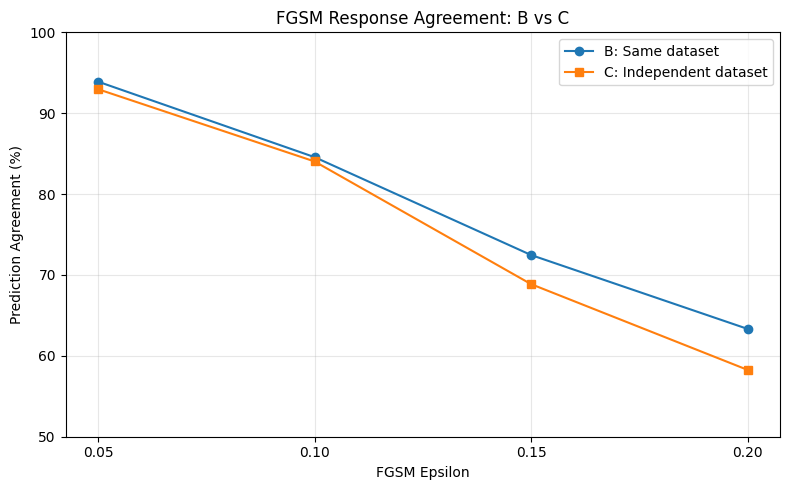

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

summary = results_df.groupby(
    ["epsilon", "model"]
)["agreement"].agg(["mean", "std"]).reset_index()

B_summary = summary[
    summary["model"].str.startswith("B_")
].groupby("epsilon")["mean"].mean()

C_summary = summary[
    summary["model"].str.startswith("C_")
].groupby("epsilon")["mean"].mean()

epsilons = sorted(results_df["epsilon"].unique())

plt.figure(figsize=(8, 5))

plt.plot(
    epsilons, B_summary.loc[epsilons],
    marker="o", label="B: Same dataset"
)

plt.plot(
    epsilons, C_summary.loc[epsilons],
    marker="s", label="C: Independent dataset"
)

plt.xlabel("FGSM Epsilon")
plt.ylabel("Prediction Agreement (%)")
plt.title("FGSM Response Agreement: B vs C")
plt.xticks(epsilons)
plt.ylim(50, 100)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

# 본 실험 전용 폴더 생성
MAIN_DIR = "/content/drive/MyDrive/FGSM_Research/Main_Experiment"

MAIN_CHECKPOINT_DIR = os.path.join(MAIN_DIR, "checkpoints")
MAIN_RESULT_DIR = os.path.join(MAIN_DIR, "results")

os.makedirs(MAIN_CHECKPOINT_DIR, exist_ok=True)
os.makedirs(MAIN_RESULT_DIR, exist_ok=True)

print("본 실험 폴더 생성 완료!")
print("체크포인트:", MAIN_CHECKPOINT_DIR)
print("결과 저장:", MAIN_RESULT_DIR)


본 실험 폴더 생성 완료!
체크포인트: /content/drive/MyDrive/FGSM_Research/Main_Experiment/checkpoints
결과 저장: /content/drive/MyDrive/FGSM_Research/Main_Experiment/results


In [ ]:

from torch.utils.data import Subset, DataLoader
from sklearn.model_selection import train_test_split
import numpy as np

# 전체 학습 데이터 인덱스와 정답
labels = np.array(train_dataset.targets)
all_indices = np.arange(len(train_dataset))

# D_private와 D_independent 분리
private_indices, independent_indices = train_test_split(
    all_indices,
    test_size=0.5,
    random_state=2026,
    stratify=labels
)

# 각각 학습용 90%, 검증용 10% 분리
private_train_idx, private_val_idx = train_test_split(
    private_indices,
    test_size=0.1,
    random_state=2026,
    stratify=labels[private_indices]
)

independent_train_idx, independent_val_idx = train_test_split(
    independent_indices,
    test_size=0.1,
    random_state=2026,
    stratify=labels[independent_indices]
)

# 데이터셋 구성
D_private_train = Subset(train_dataset, private_train_idx)
D_private_val = Subset(train_dataset, private_val_idx)

D_independent_train = Subset(train_dataset, independent_train_idx)
D_independent_val = Subset(train_dataset, independent_val_idx)

# 최종 테스트 데이터
D_test = test_dataset

# 데이터 개수 확인
print("Private 학습:", len(D_private_train))
print("Private 검증:", len(D_private_val))
print("Independent 학습:", len(D_independent_train))
print("Independent 검증:", len(D_independent_val))
print("최종 테스트:", len(D_test))

print(
    "학습 데이터 중복:",
    len(set(private_train_idx) & set(independent_train_idx))
)


Private 학습: 27000
Private 검증: 3000
Independent 학습: 27000
Independent 검증: 3000
최종 테스트: 10000
학습 데이터 중복: 0


/tmp/ipykernel_1609/565784728.py:6: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  labels = np.array(train_dataset.targets)


In [ ]:

# 본 실험용 DataLoader

BATCH_SIZE = 128

private_train_loader = DataLoader(
    D_private_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

private_val_loader = DataLoader(
    D_private_val,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

independent_train_loader = DataLoader(
    D_independent_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

independent_val_loader = DataLoader(
    D_independent_val,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

final_test_loader = DataLoader(
    D_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("본 실험용 DataLoader 생성 완료!")


본 실험용 DataLoader 생성 완료!


In [ ]:

def evaluate_v2(model, loader):
    model.eval()
    correct = 0
    total = 0
    total_loss = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            preds = outputs.argmax(dim=1)

            correct += (preds == labels).sum().item()
            total += labels.size(0)

    accuracy = 100 * correct / total
    avg_loss = total_loss / total

    return accuracy, avg_loss


def train_model_v2(
    model,
    train_loader,
    val_loader,
    model_name,
    epochs=5,
    resume=False
):
    optimizer = torch.optim.Adam(
        model.parameters(), lr=0.001
    )

    start_epoch = 0
    best_accuracy = 0.0

    latest_path = os.path.join(
        MAIN_CHECKPOINT_DIR,
        f"{model_name}_latest.pth"
    )

    best_path = os.path.join(
        MAIN_CHECKPOINT_DIR,
        f"{model_name}_best.pth"
    )

    if resume and os.path.exists(latest_path):
        checkpoint = torch.load(
            latest_path, map_location=device
        )

        model.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

        start_epoch = checkpoint["epoch"]
        best_accuracy = checkpoint["best_accuracy"]

        print(f"{model_name}: {start_epoch} epoch부터 재개")

    for epoch in range(start_epoch, epochs):
        model.train()
        running_loss = 0.0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            total += labels.size(0)

        train_loss = running_loss / total

        # 검증 데이터로 평가
        val_accuracy, val_loss = evaluate_v2(
            model, val_loader
        )

        print(
            f"{model_name} | Epoch [{epoch+1}/{epochs}] "
            f"| Train Loss: {train_loss:.4f} "
            f"| Val Loss: {val_loss:.4f} "
            f"| Val Accuracy: {val_accuracy:.2f}%"
        )

        # 최신 학습 상태 저장
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_accuracy": max(best_accuracy, val_accuracy)
        }, latest_path)

        # 검증 정확도가 가장 높을 때 best 저장
        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy

            torch.save({
                "model_state_dict": model.state_dict(),
                "val_accuracy": val_accuracy,
                "epoch": epoch + 1
            }, best_path)

    # 최고 검증 성능 모델 불러오기
    best_checkpoint = torch.load(
        best_path, map_location=device
    )

    model.load_state_dict(
        best_checkpoint["model_state_dict"]
    )

    print(f"\n{model_name} 학습 완료!")
    print(f"최고 검증 정확도: {best_accuracy:.2f}%")

    return model


In [ ]:

# A 기준 모델 학습
torch.manual_seed(1001)

model_A_main = CNN().to(device)

model_A_main = train_model_v2(
    model=model_A_main,
    train_loader=private_train_loader,
    val_loader=private_val_loader,
    model_name="main_model_A",
    epochs=5
)


main_model_A | Epoch [1/5] | Train Loss: 0.4174 | Val Loss: 0.1196 | Val Accuracy: 96.33%
main_model_A | Epoch [2/5] | Train Loss: 0.0990 | Val Loss: 0.0768 | Val Accuracy: 97.67%
main_model_A | Epoch [3/5] | Train Loss: 0.0683 | Val Loss: 0.0551 | Val Accuracy: 98.30%
main_model_A | Epoch [4/5] | Train Loss: 0.0523 | Val Loss: 0.0519 | Val Accuracy: 98.37%
main_model_A | Epoch [5/5] | Train Loss: 0.0430 | Val Loss: 0.0489 | Val Accuracy: 98.20%

main_model_A 학습 완료!
최고 검증 정확도: 98.37%


In [ ]:

# B 의심 모델 학습
torch.manual_seed(2001)

model_B_main = CNN().to(device)

model_B_main = train_model_v2(
    model=model_B_main,
    train_loader=private_train_loader,
    val_loader=private_val_loader,
    model_name="main_model_B",
    epochs=5
)


main_model_B | Epoch [1/5] | Train Loss: 0.4045 | Val Loss: 0.1309 | Val Accuracy: 95.67%
main_model_B | Epoch [2/5] | Train Loss: 0.1014 | Val Loss: 0.0826 | Val Accuracy: 97.47%
main_model_B | Epoch [3/5] | Train Loss: 0.0696 | Val Loss: 0.0570 | Val Accuracy: 98.27%
main_model_B | Epoch [4/5] | Train Loss: 0.0551 | Val Loss: 0.0405 | Val Accuracy: 98.63%
main_model_B | Epoch [5/5] | Train Loss: 0.0423 | Val Loss: 0.0371 | Val Accuracy: 98.77%

main_model_B 학습 완료!
최고 검증 정확도: 98.77%


In [ ]:

# C 비교 모델 학습
torch.manual_seed(3001)

model_C_main = CNN().to(device)

model_C_main = train_model_v2(
    model=model_C_main,
    train_loader=independent_train_loader,
    val_loader=independent_val_loader,
    model_name="main_model_C",
    epochs=5
)


main_model_C | Epoch [1/5] | Train Loss: 0.3963 | Val Loss: 0.1198 | Val Accuracy: 96.53%
main_model_C | Epoch [2/5] | Train Loss: 0.0964 | Val Loss: 0.0825 | Val Accuracy: 97.70%
main_model_C | Epoch [3/5] | Train Loss: 0.0633 | Val Loss: 0.0590 | Val Accuracy: 98.23%
main_model_C | Epoch [4/5] | Train Loss: 0.0490 | Val Loss: 0.0833 | Val Accuracy: 97.70%
main_model_C | Epoch [5/5] | Train Loss: 0.0389 | Val Loss: 0.0602 | Val Accuracy: 98.10%

main_model_C 학습 완료!
최고 검증 정확도: 98.23%


In [ ]:

# 최종 테스트 데이터 평가
main_models = {
    "A": model_A_main,
    "B": model_B_main,
    "C": model_C_main
}

test_results = []

for name, model in main_models.items():
    accuracy, loss = evaluate_v2(
        model, final_test_loader
    )

    test_results.append({
        "model": name,
        "test_accuracy": accuracy,
        "test_loss": loss
    })

test_df = pd.DataFrame(test_results)

print("최종 테스트 결과")
display(test_df.round(4))

test_df.to_csv(
    os.path.join(MAIN_RESULT_DIR, "clean_test_results.csv"),
    index=False
)


최종 테스트 결과


,model,test_accuracy,test_loss
0,A,98.46,0.0478
1,B,98.75,0.0387
2,C,98.26,0.0484


In [ ]:

# 블랙박스 예측 인터페이스
# 내부 모델은 예측 함수 안에서만 사용

def make_blackbox_api(model):
    model.eval()

    def predict(images):
        images = images.to(device)

        with torch.no_grad():
            outputs = model(images)
            predicted_labels = outputs.argmax(dim=1)

        return predicted_labels.cpu()

    return predict


# B와 C의 예측 API 생성
B_blackbox = make_blackbox_api(model_B_main)
C_blackbox = make_blackbox_api(model_C_main)

print("B 블랙박스 API 생성 완료")
print("C 블랙박스 API 생성 완료")


B 블랙박스 API 생성 완료
C 블랙박스 API 생성 완료


In [ ]:

# 본 실험: 블랙박스 FGSM 응답 비교

epsilons = [0.05, 0.10, 0.15, 0.20]

model_A_main.eval()

main_results = []

for eps in epsilons:
    total = 0

    agreement_AB = 0
    agreement_AC = 0

    correct_A = 0
    correct_B = 0
    correct_C = 0

    for images, labels in final_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        # A만 내부 기울기를 이용해 FGSM 생성
        adv_images = fgsm_attack(
            model_A_main,
            images,
            labels,
            eps
        )

        # A의 예측
        with torch.no_grad():
            A_preds = model_A_main(
                adv_images
            ).argmax(dim=1).cpu()

        # B와 C는 블랙박스 API로 예측값만 반환
        B_preds = B_blackbox(adv_images)
        C_preds = C_blackbox(adv_images)

        labels_cpu = labels.cpu()

        # A-B, A-C 예측 일치 횟수
        agreement_AB += (A_preds == B_preds).sum().item()
        agreement_AC += (A_preds == C_preds).sum().item()

        # 실제 정답과 비교한 정확도
        correct_A += (A_preds == labels_cpu).sum().item()
        correct_B += (B_preds == labels_cpu).sum().item()
        correct_C += (C_preds == labels_cpu).sum().item()

        total += len(labels)

    main_results.extend([
        {
            "epsilon": eps,
            "comparison": "A-B",
            "agreement": agreement_AB / total * 100,
            "A_accuracy": correct_A / total * 100,
            "target_accuracy": correct_B / total * 100
        },
        {
            "epsilon": eps,
            "comparison": "A-C",
            "agreement": agreement_AC / total * 100,
            "A_accuracy": correct_A / total * 100,
            "target_accuracy": correct_C / total * 100
        }
    ])

    print(f"epsilon={eps:.2f} 실험 완료")

# 결과 정리
main_results_df = pd.DataFrame(main_results)

print("\n본 실험 결과")
display(main_results_df.round(2))

# 구글 드라이브 저장
main_results_df.to_csv(
    os.path.join(
        MAIN_RESULT_DIR,
        "blackbox_fgsm_results.csv"
    ),
    index=False
)

print("본 실험 결과 저장 완료!")


epsilon=0.05 실험 완료
epsilon=0.10 실험 완료
epsilon=0.15 실험 완료
epsilon=0.20 실험 완료

본 실험 결과


,epsilon,comparison,agreement,A_accuracy,target_accuracy
0,0.05,A-B,96.70,94.74,96.70
1,0.05,A-C,95.81,94.74,96.45
2,0.10,A-B,90.91,85.06,92.40
3,0.10,A-C,89.63,85.06,92.19
4,0.15,A-B,80.88,66.32,82.62
5,0.15,A-C,78.43,66.32,83.45
6,0.20,A-B,71.33,39.70,63.52
7,0.20,A-C,65.80,39.70,67.82


본 실험 결과 저장 완료!


In [ ]:

import numpy as np
import pandas as pd

# 이미지별 일치 여부 저장
paired_results = {}

for eps in epsilons:
    ab_list = []
    ac_list = []

    for images, labels in final_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        # A로 FGSM 이미지 생성
        adv_images = fgsm_attack(
            model_A_main, images, labels, eps
        )

        # A의 예측
        with torch.no_grad():
            A_preds = model_A_main(
                adv_images
            ).argmax(dim=1).cpu().numpy()

        # B와 C는 예측값만 반환
        B_preds = B_blackbox(adv_images).numpy()
        C_preds = C_blackbox(adv_images).numpy()

        # 이미지별 일치 여부
        ab_list.extend((A_preds == B_preds).astype(int))
        ac_list.extend((A_preds == C_preds).astype(int))

    paired_results[eps] = (
        np.array(ab_list),
        np.array(ac_list)
    )

# Paired bootstrap
rng = np.random.default_rng(42)
bootstrap_iterations = 5000

bootstrap_summary = []

for eps, (ab, ac) in paired_results.items():
    differences = ab - ac
    observed_diff = differences.mean() * 100

    bootstrap_diffs = []

    for _ in range(bootstrap_iterations):
        indices = rng.integers(
            0, len(differences), len(differences)
        )

        sampled_diff = differences[indices].mean() * 100
        bootstrap_diffs.append(sampled_diff)

    ci_low, ci_high = np.percentile(
        bootstrap_diffs, [2.5, 97.5]
    )

    bootstrap_summary.append({
        "epsilon": eps,
        "AB_minus_AC": observed_diff,
        "CI_lower_95": ci_low,
        "CI_upper_95": ci_high
    })

bootstrap_df = pd.DataFrame(bootstrap_summary)

display(bootstrap_df.round(3))

bootstrap_df.to_csv(
    os.path.join(
        MAIN_RESULT_DIR,
        "paired_bootstrap_results.csv"
    ),
    index=False
)

print("부트스트랩 분석 및 저장 완료!")


,epsilon,AB_minus_AC,CI_lower_95,CI_upper_95
0,0.05,0.89,0.55,1.24
1,0.10,1.28,0.81,1.77
2,0.15,2.45,1.80,3.11
3,0.20,5.53,4.69,6.39


부트스트랩 분석 및 저장 완료!


In [ ]:

torch.manual_seed(2002)

model_B_seed2 = CNN().to(device)

model_B_seed2 = train_model_v2(
    model_B_seed2,
    private_train_loader,
    private_val_loader,
    "main_model_B_seed2",
    epochs=5
)


main_model_B_seed2 | Epoch [1/5] | Train Loss: 0.4216 | Val Loss: 0.1154 | Val Accuracy: 96.63%
main_model_B_seed2 | Epoch [2/5] | Train Loss: 0.1014 | Val Loss: 0.0898 | Val Accuracy: 97.00%
main_model_B_seed2 | Epoch [3/5] | Train Loss: 0.0701 | Val Loss: 0.0497 | Val Accuracy: 98.57%
main_model_B_seed2 | Epoch [4/5] | Train Loss: 0.0520 | Val Loss: 0.0527 | Val Accuracy: 98.13%
main_model_B_seed2 | Epoch [5/5] | Train Loss: 0.0441 | Val Loss: 0.0511 | Val Accuracy: 98.37%

main_model_B_seed2 학습 완료!
최고 검증 정확도: 98.57%


In [ ]:

torch.manual_seed(2003)

model_B_seed3 = CNN().to(device)

model_B_seed3 = train_model_v2(
    model_B_seed3,
    private_train_loader,
    private_val_loader,
    "main_model_B_seed3",
    epochs=5
)


main_model_B_seed3 | Epoch [1/5] | Train Loss: 0.4231 | Val Loss: 0.1152 | Val Accuracy: 96.37%
main_model_B_seed3 | Epoch [2/5] | Train Loss: 0.1003 | Val Loss: 0.0625 | Val Accuracy: 98.27%
main_model_B_seed3 | Epoch [3/5] | Train Loss: 0.0703 | Val Loss: 0.0804 | Val Accuracy: 97.43%
main_model_B_seed3 | Epoch [4/5] | Train Loss: 0.0535 | Val Loss: 0.0457 | Val Accuracy: 98.37%
main_model_B_seed3 | Epoch [5/5] | Train Loss: 0.0426 | Val Loss: 0.0410 | Val Accuracy: 98.40%

main_model_B_seed3 학습 완료!
최고 검증 정확도: 98.40%


In [ ]:

torch.manual_seed(2004)

model_B_seed4 = CNN().to(device)

model_B_seed4 = train_model_v2(
    model_B_seed4,
    private_train_loader,
    private_val_loader,
    "main_model_B_seed4",
    epochs=5
)


main_model_B_seed4 | Epoch [1/5] | Train Loss: 0.4257 | Val Loss: 0.1200 | Val Accuracy: 96.53%
main_model_B_seed4 | Epoch [2/5] | Train Loss: 0.0991 | Val Loss: 0.0736 | Val Accuracy: 97.77%
main_model_B_seed4 | Epoch [3/5] | Train Loss: 0.0694 | Val Loss: 0.0618 | Val Accuracy: 97.97%
main_model_B_seed4 | Epoch [4/5] | Train Loss: 0.0515 | Val Loss: 0.0483 | Val Accuracy: 98.63%
main_model_B_seed4 | Epoch [5/5] | Train Loss: 0.0434 | Val Loss: 0.0392 | Val Accuracy: 98.97%

main_model_B_seed4 학습 완료!
최고 검증 정확도: 98.97%


In [ ]:

torch.manual_seed(3002)

model_C_seed2 = CNN().to(device)

model_C_seed2 = train_model_v2(
    model_C_seed2,
    independent_train_loader,
    independent_val_loader,
    "main_model_C_seed2",
    epochs=5
)


main_model_C_seed2 | Epoch [1/5] | Train Loss: 0.4176 | Val Loss: 0.1449 | Val Accuracy: 95.80%
main_model_C_seed2 | Epoch [2/5] | Train Loss: 0.1011 | Val Loss: 0.0907 | Val Accuracy: 97.37%
main_model_C_seed2 | Epoch [3/5] | Train Loss: 0.0690 | Val Loss: 0.0835 | Val Accuracy: 97.50%
main_model_C_seed2 | Epoch [4/5] | Train Loss: 0.0526 | Val Loss: 0.0640 | Val Accuracy: 98.27%
main_model_C_seed2 | Epoch [5/5] | Train Loss: 0.0431 | Val Loss: 0.0633 | Val Accuracy: 98.23%

main_model_C_seed2 학습 완료!
최고 검증 정확도: 98.27%


In [ ]:

torch.manual_seed(3003)

model_C_seed3 = CNN().to(device)

model_C_seed3 = train_model_v2(
    model_C_seed3,
    independent_train_loader,
    independent_val_loader,
    "main_model_C_seed3",
    epochs=5
)


main_model_C_seed3 | Epoch [1/5] | Train Loss: 0.4455 | Val Loss: 0.1392 | Val Accuracy: 96.27%
main_model_C_seed3 | Epoch [2/5] | Train Loss: 0.1002 | Val Loss: 0.1042 | Val Accuracy: 96.83%
main_model_C_seed3 | Epoch [3/5] | Train Loss: 0.0690 | Val Loss: 0.0805 | Val Accuracy: 97.70%
main_model_C_seed3 | Epoch [4/5] | Train Loss: 0.0529 | Val Loss: 0.0734 | Val Accuracy: 97.93%
main_model_C_seed3 | Epoch [5/5] | Train Loss: 0.0427 | Val Loss: 0.0599 | Val Accuracy: 98.40%

main_model_C_seed3 학습 완료!
최고 검증 정확도: 98.40%


In [ ]:

torch.manual_seed(3004)

model_C_seed4 = CNN().to(device)

model_C_seed4 = train_model_v2(
    model_C_seed4,
    independent_train_loader,
    independent_val_loader,
    "main_model_C_seed4",
    epochs=5
)


main_model_C_seed4 | Epoch [1/5] | Train Loss: 0.4054 | Val Loss: 0.1328 | Val Accuracy: 96.10%
main_model_C_seed4 | Epoch [2/5] | Train Loss: 0.1018 | Val Loss: 0.0821 | Val Accuracy: 97.67%
main_model_C_seed4 | Epoch [3/5] | Train Loss: 0.0696 | Val Loss: 0.0682 | Val Accuracy: 98.23%
main_model_C_seed4 | Epoch [4/5] | Train Loss: 0.0534 | Val Loss: 0.0745 | Val Accuracy: 97.80%
main_model_C_seed4 | Epoch [5/5] | Train Loss: 0.0434 | Val Loss: 0.0580 | Val Accuracy: 98.63%

main_model_C_seed4 학습 완료!
최고 검증 정확도: 98.63%


In [ ]:

# 추가 B 모델 블랙박스 API
B_seed2_blackbox = make_blackbox_api(model_B_seed2)
B_seed3_blackbox = make_blackbox_api(model_B_seed3)
B_seed4_blackbox = make_blackbox_api(model_B_seed4)

# 추가 C 모델 블랙박스 API
C_seed2_blackbox = make_blackbox_api(model_C_seed2)
C_seed3_blackbox = make_blackbox_api(model_C_seed3)
C_seed4_blackbox = make_blackbox_api(model_C_seed4)

print("추가 B 모델 3개 블랙박스 API 생성 완료")
print("추가 C 모델 3개 블랙박스 API 생성 완료")


추가 B 모델 3개 블랙박스 API 생성 완료
추가 C 모델 3개 블랙박스 API 생성 완료


In [ ]:

# 여러 초기값 모델의 블랙박스 FGSM 평가

B_apis = {
    "B_seed1": B_blackbox,
    "B_seed2": B_seed2_blackbox,
    "B_seed3": B_seed3_blackbox,
    "B_seed4": B_seed4_blackbox
}

C_apis = {
    "C_seed1": C_blackbox,
    "C_seed2": C_seed2_blackbox,
    "C_seed3": C_seed3_blackbox,
    "C_seed4": C_seed4_blackbox
}

epsilons = [0.05, 0.10, 0.15, 0.20]

multi_seed_results = []

model_A_main.eval()

for eps in epsilons:
    # 모델별 일치 횟수
    agreement_counts = {
        name: 0 for name in list(B_apis) + list(C_apis)
    }

    total = 0

    for images, labels in final_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        # A의 기울기로 FGSM 생성
        adv_images = fgsm_attack(
            model_A_main, images, labels, eps
        )

        # A의 예측
        with torch.no_grad():
            A_preds = model_A_main(
                adv_images
            ).argmax(dim=1).cpu()

        # B 모델 4개 평가
        for name, api in B_apis.items():
            preds = api(adv_images)
            agreement_counts[name] += (
                A_preds == preds
            ).sum().item()

        # C 모델 4개 평가
        for name, api in C_apis.items():
            preds = api(adv_images)
            agreement_counts[name] += (
                A_preds == preds
            ).sum().item()

        total += len(labels)

    # 결과 저장
    for name, count in agreement_counts.items():
        multi_seed_results.append({
            "epsilon": eps,
            "model": name,
            "group": name[0],
            "agreement": count / total * 100
        })

    print(f"epsilon={eps:.2f} 평가 완료")

multi_seed_df = pd.DataFrame(multi_seed_results)

print("\n모델별 일치율")
display(
    multi_seed_df.pivot(
        index="model",
        columns="epsilon",
        values="agreement"
    ).round(2)
)

multi_seed_df.to_csv(
    os.path.join(
        MAIN_RESULT_DIR,
        "multi_seed_agreement_results.csv"
    ),
    index=False
)

print("다중 초기값 평가 결과 저장 완료!")


epsilon=0.05 평가 완료
epsilon=0.10 평가 완료
epsilon=0.15 평가 완료
epsilon=0.20 평가 완료

모델별 일치율


epsilon,0.05,0.10,0.15,0.20
model,,,,
B_seed1,96.70,90.91,80.88,71.33
B_seed2,96.66,91.20,82.19,72.03
B_seed3,96.18,90.20,80.66,70.71
B_seed4,95.99,89.48,77.85,64.92
C_seed1,95.81,89.63,78.43,65.80
C_seed2,95.76,89.24,77.35,65.41
C_seed3,95.88,89.14,77.03,63.57
C_seed4,96.05,89.45,77.64,66.38


다중 초기값 평가 결과 저장 완료!


In [ ]:

# B 그룹과 C 그룹의 평균 및 표준편차 계산

group_summary = (
    multi_seed_df
    .groupby(["epsilon", "group"])["agreement"]
    .agg(["mean", "std"])
    .reset_index()
)

print("그룹별 평균 및 표준편차")
display(group_summary.round(3))

# B 평균 - C 평균 차이 계산
mean_table = multi_seed_df.pivot_table(
    index="epsilon",
    columns="group",
    values="agreement",
    aggfunc="mean"
)

mean_table["B_minus_C"] = (
    mean_table["B"] - mean_table["C"]
)

print("\nB 그룹과 C 그룹의 평균 일치율 차이")
display(mean_table.round(3))

# CSV 저장
group_summary.to_csv(
    os.path.join(
        MAIN_RESULT_DIR,
        "group_mean_std_results.csv"
    ),
    index=False
)

mean_table.to_csv(
    os.path.join(
        MAIN_RESULT_DIR,
        "group_difference_results.csv"
    )
)

print("그룹 통계 결과 저장 완료!")


그룹별 평균 및 표준편차


,epsilon,group,mean,std
0,0.05,B,96.382,0.353
1,0.05,C,95.875,0.127
2,0.10,B,90.448,0.770
3,0.10,C,89.365,0.219
4,0.15,B,80.395,1.826
5,0.15,C,77.612,0.599
6,0.20,B,69.748,3.263
7,0.20,C,65.290,1.214



B 그룹과 C 그룹의 평균 일치율 차이


group,B,C,B_minus_C
epsilon,,,
0.05,96.382,95.875,0.507
0.10,90.448,89.365,1.083
0.15,80.395,77.612,2.782
0.20,69.748,65.290,4.458


그룹 통계 결과 저장 완료!


In [ ]:

# 1단계: 원본 이미지(Clean) 응답 일치율 비교

clean_results = []

model_A_main.eval()

for images, labels in final_test_loader:
    images = images.to(device)

    # A의 원본 이미지 예측
    with torch.no_grad():
        A_preds = model_A_main(images).argmax(dim=1).cpu()

    # B 모델 4개
    for name, api in B_apis.items():
        preds = api(images)

        clean_results.append({
            "model": name,
            "group": "B",
            "agreement": (A_preds == preds).sum().item(),
            "total": len(labels)
        })

    # C 모델 4개
    for name, api in C_apis.items():
        preds = api(images)

        clean_results.append({
            "model": name,
            "group": "C",
            "agreement": (A_preds == preds).sum().item(),
            "total": len(labels)
        })

# 모델별 전체 일치율 계산
clean_df = pd.DataFrame(clean_results)

clean_summary = (
    clean_df.groupby(["model", "group"])
    .agg(
        agreement=("agreement", "sum"),
        total=("total", "sum")
    )
    .reset_index()
)

clean_summary["agreement_rate"] = (
    clean_summary["agreement"] /
    clean_summary["total"] * 100
)

print("모델별 원본 이미지 일치율")
display(clean_summary.round(3))

# 그룹별 평균과 표준편차
clean_group_summary = (
    clean_summary.groupby("group")["agreement_rate"]
    .agg(["mean", "std"])
    .reset_index()
)

print("\n그룹별 원본 이미지 일치율")
display(clean_group_summary.round(3))

# 결과 저장
clean_summary.to_csv(
    os.path.join(MAIN_RESULT_DIR, "clean_agreement_results.csv"),
    index=False
)

clean_group_summary.to_csv(
    os.path.join(MAIN_RESULT_DIR, "clean_group_summary.csv"),
    index=False
)

print("원본 이미지 비교 결과 저장 완료!")


모델별 원본 이미지 일치율


,model,group,agreement,total,agreement_rate
0,B_seed1,B,9882,10000,98.82
1,B_seed2,B,9866,10000,98.66
2,B_seed3,B,9866,10000,98.66
3,B_seed4,B,9878,10000,98.78
4,C_seed1,C,9838,10000,98.38
5,C_seed2,C,9834,10000,98.34
6,C_seed3,C,9864,10000,98.64
7,C_seed4,C,9860,10000,98.60



그룹별 원본 이미지 일치율


,group,mean,std
0,B,98.73,0.082
1,C,98.49,0.152


원본 이미지 비교 결과 저장 완료!


In [ ]:

# 원본 이미지와 FGSM 그룹 차이 통합

clean_gap = (
    clean_group_summary.loc[
        clean_group_summary["group"] == "B", "mean"
    ].iloc[0]
    -
    clean_group_summary.loc[
        clean_group_summary["group"] == "C", "mean"
    ].iloc[0]
)

comparison_rows = [{
    "condition": "Clean",
    "B_minus_C": clean_gap,
    "additional_gap": 0.0
}]

for eps in epsilons:
    B_mean = mean_table.loc[eps, "B"]
    C_mean = mean_table.loc[eps, "C"]

    gap = B_mean - C_mean

    comparison_rows.append({
        "condition": f"FGSM_{eps:.2f}",
        "B_minus_C": gap,
        "additional_gap": gap - clean_gap
    })

comparison_df = pd.DataFrame(comparison_rows)

display(comparison_df.round(3))

comparison_df.to_csv(
    os.path.join(
        MAIN_RESULT_DIR,
        "clean_vs_fgsm_gap_results.csv"
    ),
    index=False
)

print("원본-FGSM 통합 비교표 저장 완료!")


,condition,B_minus_C,additional_gap
0,Clean,0.240,0.000
1,FGSM_0.05,0.507,0.267
2,FGSM_0.10,1.083,0.843
3,FGSM_0.15,2.782,2.543
4,FGSM_0.20,4.458,4.218


원본-FGSM 통합 비교표 저장 완료!


In [ ]:

# 이미지별 원본 및 FGSM 응답 비교 데이터 수집

clean_A = []
clean_B = {name: [] for name in B_apis}
clean_C = {name: [] for name in C_apis}

adv_data = {
    eps: {
        "A": [],
        "B": {name: [] for name in B_apis},
        "C": {name: [] for name in C_apis}
    }
    for eps in epsilons
}

model_A_main.eval()

for images, labels in final_test_loader:
    images = images.to(device)
    labels = labels.to(device)

    # 원본 이미지 예측
    with torch.no_grad():
        A_clean = model_A_main(images).argmax(dim=1).cpu()

    clean_A.append(A_clean.numpy())

    for name, api in B_apis.items():
        preds = api(images)
        clean_B[name].append((A_clean == preds).numpy())

    for name, api in C_apis.items():
        preds = api(images)
        clean_C[name].append((A_clean == preds).numpy())

    # epsilon별 FGSM 예측
    for eps in epsilons:
        adv_images = fgsm_attack(
            model_A_main, images, labels, eps
        )

        with torch.no_grad():
            A_adv = model_A_main(
                adv_images
            ).argmax(dim=1).cpu()

        adv_data[eps]["A"].append(A_adv.numpy())

        for name, api in B_apis.items():
            preds = api(adv_images)
            adv_data[eps]["B"][name].append(
                (A_adv == preds).numpy()
            )

        for name, api in C_apis.items():
            preds = api(adv_images)
            adv_data[eps]["C"][name].append(
                (A_adv == preds).numpy()
            )

print("이미지별 원본 및 FGSM 응답 수집 완료!")


이미지별 원본 및 FGSM 응답 수집 완료!


In [ ]:

import numpy as np
import pandas as pd

# 이미지별 배열 합치기
clean_B_arr = {
    name: np.concatenate(values)
    for name, values in clean_B.items()
}
clean_C_arr = {
    name: np.concatenate(values)
    for name, values in clean_C.items()
}

adv_B_arr = {
    eps: {
        name: np.concatenate(values)
        for name, values in adv_data[eps]["B"].items()
    }
    for eps in epsilons
}

adv_C_arr = {
    eps: {
        name: np.concatenate(values)
        for name, values in adv_data[eps]["C"].items()
    }
    for eps in epsilons
}

# 이미지별 그룹 평균 일치율
clean_B_mean = np.mean(
    np.stack(list(clean_B_arr.values())), axis=0
)
clean_C_mean = np.mean(
    np.stack(list(clean_C_arr.values())), axis=0
)

# 원본에서 B-C 차이
clean_gap_per_image = clean_B_mean - clean_C_mean

# Bootstrap
rng = np.random.default_rng(2026)
n_images = len(clean_gap_per_image)
n_bootstrap = 5000

bootstrap_rows = []

for eps in epsilons:
    B_mean = np.mean(
        np.stack(list(adv_B_arr[eps].values())), axis=0
    )
    C_mean = np.mean(
        np.stack(list(adv_C_arr[eps].values())), axis=0
    )

    # FGSM에서의 B-C 차이
    adv_gap_per_image = B_mean - C_mean

    # 원본 대비 추가로 커진 차이
    additional_gap = adv_gap_per_image - clean_gap_per_image

    # 이미지 단위 paired bootstrap
    boot_values = np.empty(n_bootstrap)

    for i in range(n_bootstrap):
        indices = rng.integers(0, n_images, n_images)
        boot_values[i] = additional_gap[indices].mean() * 100

    bootstrap_rows.append({
        "epsilon": eps,
        "additional_gap_pp": additional_gap.mean() * 100,
        "CI_lower_95": np.percentile(boot_values, 2.5),
        "CI_upper_95": np.percentile(boot_values, 97.5)
    })

bootstrap_df = pd.DataFrame(bootstrap_rows)

display(bootstrap_df.round(3))


,epsilon,additional_gap_pp,CI_lower_95,CI_upper_95
0,0.05,0.267,0.057,0.485
1,0.10,0.842,0.537,1.153
2,0.15,2.545,2.125,2.960
3,0.20,4.217,3.702,4.728


In [ ]:

from scipy.stats import ttest_ind
import numpy as np
import pandas as pd

# 각 모델의 원본 일치율
clean_rates = {}

for name, values in clean_B_arr.items():
    clean_rates[name] = np.mean(values) * 100

for name, values in clean_C_arr.items():
    clean_rates[name] = np.mean(values) * 100

# 각 epsilon에서 모델별 '원본 대비 일치율 변화량' 계산
test_rows = []

for eps in epsilons:
    B_deltas = []
    C_deltas = []

    for name, values in adv_B_arr[eps].items():
        adv_rate = np.mean(values) * 100
        B_deltas.append(adv_rate - clean_rates[name])

    for name, values in adv_C_arr[eps].items():
        adv_rate = np.mean(values) * 100
        C_deltas.append(adv_rate - clean_rates[name])

    t_stat, p_value = ttest_ind(
        B_deltas, C_deltas, equal_var=False
    )

    test_rows.append({
        "epsilon": eps,
        "B_delta_mean": np.mean(B_deltas),
        "C_delta_mean": np.mean(C_deltas),
        "B_minus_C_delta": np.mean(B_deltas) - np.mean(C_deltas),
        "t_stat": t_stat,
        "p_raw": p_value
    })

test_df = pd.DataFrame(test_rows)

# Holm 다중비교 보정
p_values = test_df["p_raw"].values
m = len(p_values)
order = np.argsort(p_values)
adjusted = np.empty(m)

running_max = 0

for rank, idx in enumerate(order):
    corrected = (m - rank) * p_values[idx]
    running_max = max(running_max, corrected)
    adjusted[idx] = min(running_max, 1.0)

test_df["p_holm"] = adjusted

display(test_df.round(4))


,epsilon,B_delta_mean,C_delta_mean,B_minus_C_delta,t_stat,p_raw,p_holm
0,0.05,-2.3475,-2.6150,0.2675,1.4395,0.2344,0.263
1,0.10,-8.2825,-9.1250,0.8425,1.9837,0.1205,0.263
2,0.15,-18.3325,-20.8775,2.5450,2.5616,0.0657,0.263
3,0.20,-28.9825,-33.2000,4.2175,2.3847,0.0775,0.263


In [ ]:

class CNN_Alt(nn.Module):
    def __init__(self):
        super(CNN_Alt, self).__init__()

        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)

        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(x, 2)

        x = F.relu(self.conv2(x))
        x = F.max_pool2d(x, 2)

        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x


# 모델 구조 확인
model_alt = CNN_Alt().to(device)

print(model_alt)


CNN_Alt(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [ ]:

# B_alt: D_private_train으로 학습
torch.manual_seed(4001)

model_B_alt = CNN_Alt().to(device)

model_B_alt = train_model_v2(
    model=model_B_alt,
    train_loader=private_train_loader,
    val_loader=private_val_loader,
    model_name="B_alt",
    epochs=5
)

# C_alt: D_independent_train으로 학습
torch.manual_seed(5001)

model_C_alt = CNN_Alt().to(device)

model_C_alt = train_model_v2(
    model=model_C_alt,
    train_loader=independent_train_loader,
    val_loader=independent_val_loader,
    model_name="C_alt",
    epochs=5
)

print("B_alt, C_alt 학습 완료!")


B_alt | Epoch [1/5] | Train Loss: 0.5338 | Val Loss: 0.1618 | Val Accuracy: 95.00%
B_alt | Epoch [2/5] | Train Loss: 0.1323 | Val Loss: 0.0966 | Val Accuracy: 97.10%
B_alt | Epoch [3/5] | Train Loss: 0.0845 | Val Loss: 0.0711 | Val Accuracy: 97.70%
B_alt | Epoch [4/5] | Train Loss: 0.0639 | Val Loss: 0.0580 | Val Accuracy: 98.20%
B_alt | Epoch [5/5] | Train Loss: 0.0506 | Val Loss: 0.0545 | Val Accuracy: 98.33%

B_alt 학습 완료!
최고 검증 정확도: 98.33%
C_alt | Epoch [1/5] | Train Loss: 0.5355 | Val Loss: 0.1918 | Val Accuracy: 94.17%
C_alt | Epoch [2/5] | Train Loss: 0.1458 | Val Loss: 0.1182 | Val Accuracy: 96.50%
C_alt | Epoch [3/5] | Train Loss: 0.0915 | Val Loss: 0.0854 | Val Accuracy: 97.70%
C_alt | Epoch [4/5] | Train Loss: 0.0715 | Val Loss: 0.0886 | Val Accuracy: 97.57%
C_alt | Epoch [5/5] | Train Loss: 0.0520 | Val Loss: 0.0665 | Val Accuracy: 98.00%

C_alt 학습 완료!
최고 검증 정확도: 98.00%
B_alt, C_alt 학습 완료!


In [ ]:

# 테스트셋 정확도 평가
B_alt_test_acc, B_alt_test_loss = evaluate_v2(
    model_B_alt, final_test_loader
)

C_alt_test_acc, C_alt_test_loss = evaluate_v2(
    model_C_alt, final_test_loader
)

print(f"B_alt Test Accuracy: {B_alt_test_acc:.2f}%")
print(f"C_alt Test Accuracy: {C_alt_test_acc:.2f}%")

# 블랙박스 API 생성: 예측 라벨만 반환
B_alt_blackbox = make_blackbox_api(model_B_alt)
C_alt_blackbox = make_blackbox_api(model_C_alt)

print("B_alt, C_alt 블랙박스 API 생성 완료!")


B_alt Test Accuracy: 98.53%
C_alt Test Accuracy: 98.34%
B_alt, C_alt 블랙박스 API 생성 완료!


In [ ]:

alt_results = []

model_A_main.eval()

for eps in epsilons:
    total = 0
    A_correct = 0
    B_agree = 0
    C_agree = 0
    B_correct = 0
    C_correct = 0

    for images, labels in final_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        # A 모델로 FGSM 생성
        adv_images = fgsm_attack(
            model_A_main, images, labels, eps
        )

        with torch.no_grad():
            A_preds = model_A_main(adv_images).argmax(dim=1).cpu()

        # B_alt, C_alt 블랙박스 예측
        B_preds = B_alt_blackbox(adv_images)
        C_preds = C_alt_blackbox(adv_images)

        labels_cpu = labels.cpu()

        total += labels.size(0)
        A_correct += (A_preds == labels_cpu).sum().item()
        B_agree += (A_preds == B_preds).sum().item()
        C_agree += (A_preds == C_preds).sum().item()
        B_correct += (B_preds == labels_cpu).sum().item()
        C_correct += (C_preds == labels_cpu).sum().item()

    alt_results.extend([
        {
            "epsilon": eps,
            "comparison": "A-B_alt",
            "agreement": B_agree / total * 100,
            "A_accuracy": A_correct / total * 100,
            "target_accuracy": B_correct / total * 100
        },
        {
            "epsilon": eps,
            "comparison": "A-C_alt",
            "agreement": C_agree / total * 100,
            "A_accuracy": A_correct / total * 100,
            "target_accuracy": C_correct / total * 100
        }
    ])

alt_df = pd.DataFrame(alt_results)
display(alt_df.round(2))


,epsilon,comparison,agreement,A_accuracy,target_accuracy
0,0.05,A-B_alt,96.22,94.74,96.37
1,0.05,A-C_alt,95.93,94.74,96.51
2,0.10,A-B_alt,89.70,85.06,92.16
3,0.10,A-C_alt,89.46,85.06,93.14
4,0.15,A-B_alt,78.86,66.32,82.64
5,0.15,A-C_alt,76.88,66.32,85.69
6,0.20,A-B_alt,66.22,39.70,65.73
7,0.20,A-C_alt,62.53,39.70,71.98


In [ ]:

clean_alt_results = []

for images, labels in final_test_loader:
    images = images.to(device)

    with torch.no_grad():
        A_preds = model_A_main(images).argmax(dim=1).cpu()

    B_preds = B_alt_blackbox(images)
    C_preds = C_alt_blackbox(images)

    clean_alt_results.extend([
        {
            "model": "B_alt",
            "agreement": (A_preds == B_preds).sum().item(),
            "total": len(labels)
        },
        {
            "model": "C_alt",
            "agreement": (A_preds == C_preds).sum().item(),
            "total": len(labels)
        }
    ])

clean_alt_df = pd.DataFrame(clean_alt_results)

clean_alt_summary = (
    clean_alt_df.groupby("model")
    .agg(agreement=("agreement", "sum"),
         total=("total", "sum"))
    .reset_index()
)

clean_alt_summary["agreement_rate"] = (
    clean_alt_summary["agreement"] /
    clean_alt_summary["total"] * 100
)

display(clean_alt_summary.round(3))


,model,agreement,total,agreement_rate
0,B_alt,9850,10000,98.50
1,C_alt,9849,10000,98.49


In [ ]:

# 원본 이미지에서 B_alt - C_alt 차이
clean_alt_gap = (
    clean_alt_summary.loc[
        clean_alt_summary["model"] == "B_alt",
        "agreement_rate"
    ].iloc[0]
    -
    clean_alt_summary.loc[
        clean_alt_summary["model"] == "C_alt",
        "agreement_rate"
    ].iloc[0]
)

# FGSM 강도별 차이 계산
alt_gap_rows = [{
    "condition": "Clean",
    "B_alt_minus_C_alt": clean_alt_gap,
    "additional_gap": 0.0
}]

for eps in epsilons:
    B_rate = alt_df[
        (alt_df["epsilon"] == eps) &
        (alt_df["comparison"] == "A-B_alt")
    ]["agreement"].iloc[0]

    C_rate = alt_df[
        (alt_df["epsilon"] == eps) &
        (alt_df["comparison"] == "A-C_alt")
    ]["agreement"].iloc[0]

    gap = B_rate - C_rate

    alt_gap_rows.append({
        "condition": f"FGSM_{eps:.2f}",
        "B_alt_minus_C_alt": gap,
        "additional_gap": gap - clean_alt_gap
    })

alt_gap_df = pd.DataFrame(alt_gap_rows)

display(alt_gap_df.round(3))


,condition,B_alt_minus_C_alt,additional_gap
0,Clean,0.01,0.00
1,FGSM_0.05,0.29,0.28
2,FGSM_0.10,0.24,0.23
3,FGSM_0.15,1.98,1.97
4,FGSM_0.20,3.69,3.68


In [ ]:

# 기존 모델을 포함한 모델 저장용 딕셔너리
B_alt_models = {"B_alt_seed1": model_B_alt}
C_alt_models = {"C_alt_seed1": model_C_alt}

# B_alt 추가 모델 3개
for seed in [4002, 4003, 4004]:
    torch.manual_seed(seed)

    model = CNN_Alt().to(device)

    model = train_model_v2(
        model=model,
        train_loader=private_train_loader,
        val_loader=private_val_loader,
        model_name=f"B_alt_seed{seed - 4000}",
        epochs=5
    )

    B_alt_models[f"B_alt_seed{seed - 4000}"] = model


# C_alt 추가 모델 3개
for seed in [5002, 5003, 5004]:
    torch.manual_seed(seed)

    model = CNN_Alt().to(device)

    model = train_model_v2(
        model=model,
        train_loader=independent_train_loader,
        val_loader=independent_val_loader,
        model_name=f"C_alt_seed{seed - 5000}",
        epochs=5
    )

    C_alt_models[f"C_alt_seed{seed - 5000}"] = model


print("B_alt 모델 수:", len(B_alt_models))
print("C_alt 모델 수:", len(C_alt_models))


B_alt_seed2 | Epoch [1/5] | Train Loss: 0.5096 | Val Loss: 0.1631 | Val Accuracy: 94.93%
B_alt_seed2 | Epoch [2/5] | Train Loss: 0.1330 | Val Loss: 0.0913 | Val Accuracy: 97.23%
B_alt_seed2 | Epoch [3/5] | Train Loss: 0.0876 | Val Loss: 0.0670 | Val Accuracy: 98.00%
B_alt_seed2 | Epoch [4/5] | Train Loss: 0.0674 | Val Loss: 0.0565 | Val Accuracy: 98.13%
B_alt_seed2 | Epoch [5/5] | Train Loss: 0.0540 | Val Loss: 0.0559 | Val Accuracy: 98.20%

B_alt_seed2 학습 완료!
최고 검증 정확도: 98.20%
B_alt_seed3 | Epoch [1/5] | Train Loss: 0.5656 | Val Loss: 0.2068 | Val Accuracy: 93.33%
B_alt_seed3 | Epoch [2/5] | Train Loss: 0.1441 | Val Loss: 0.1082 | Val Accuracy: 96.70%
B_alt_seed3 | Epoch [3/5] | Train Loss: 0.0945 | Val Loss: 0.0996 | Val Accuracy: 96.73%
B_alt_seed3 | Epoch [4/5] | Train Loss: 0.0757 | Val Loss: 0.0664 | Val Accuracy: 97.73%
B_alt_seed3 | Epoch [5/5] | Train Loss: 0.0616 | Val Loss: 0.0571 | Val Accuracy: 98.07%

B_alt_seed3 학습 완료!
최고 검증 정확도: 98.07%
B_alt_seed4 | Epoch [1/5] | Train 

In [ ]:

B_alt_apis = {
    name: make_blackbox_api(model)
    for name, model in B_alt_models.items()
}

C_alt_apis = {
    name: make_blackbox_api(model)
    for name, model in C_alt_models.items()
}

print("B_alt API:", list(B_alt_apis.keys()))
print("C_alt API:", list(C_alt_apis.keys()))


B_alt API: ['B_alt_seed1', 'B_alt_seed2', 'B_alt_seed3', 'B_alt_seed4']
C_alt API: ['C_alt_seed1', 'C_alt_seed2', 'C_alt_seed3', 'C_alt_seed4']


In [ ]:

import numpy as np
import torch

epsilons = [0.05, 0.10, 0.15, 0.20]

# 이미지별 A와의 예측 일치 여부 저장
clean_alt_B = {name: [] for name in B_alt_apis}
clean_alt_C = {name: [] for name in C_alt_apis}

adv_alt_B = {
    eps: {name: [] for name in B_alt_apis}
    for eps in epsilons
}
adv_alt_C = {
    eps: {name: [] for name in C_alt_apis}
    for eps in epsilons
}

model_A.eval()

for images, labels in final_test_loader:
    images = images.to(device)
    labels = labels.to(device)

    # Clean 이미지에서 A의 예측
    with torch.no_grad():
        A_clean = model_A(images).argmax(dim=1).cpu()

    # Clean 이미지의 B_alt, C_alt 예측
    for name, api in B_alt_apis.items():
        pred = api(images)
        clean_alt_B[name].append((pred == A_clean).numpy())

    for name, api in C_alt_apis.items():
        pred = api(images)
        clean_alt_C[name].append((pred == A_clean).numpy())

    # FGSM 교란 이미지 평가
    for eps in epsilons:
        adv_images = fgsm_attack(model_A, images, labels, eps)

        with torch.no_grad():
            A_adv = model_A(adv_images).argmax(dim=1).cpu()

        for name, api in B_alt_apis.items():
            pred = api(adv_images)
            adv_alt_B[eps][name].append((pred == A_adv).numpy())

        for name, api in C_alt_apis.items():
            pred = api(adv_images)
            adv_alt_C[eps][name].append((pred == A_adv).numpy())

# 배치별 결과를 하나의 배열로 합치기
for name in B_alt_apis:
    clean_alt_B[name] = np.concatenate(clean_alt_B[name])

for name in C_alt_apis:
    clean_alt_C[name] = np.concatenate(clean_alt_C[name])

for eps in epsilons:
    for name in B_alt_apis:
        adv_alt_B[eps][name] = np.concatenate(adv_alt_B[eps][name])

    for name in C_alt_apis:
        adv_alt_C[eps][name] = np.concatenate(adv_alt_C[eps][name])

print("평가 이미지 수:", len(clean_alt_B["B_alt_seed1"]))
print("B_alt 모델 수:", len(B_alt_apis))
print("C_alt 모델 수:", len(C_alt_apis))
print("FGSM 평가 완료:", epsilons)


평가 이미지 수: 10000
B_alt 모델 수: 4
C_alt 모델 수: 4
FGSM 평가 완료: [0.05, 0.1, 0.15, 0.2]


In [ ]:

import pandas as pd

rows = []

# Clean 결과
for group, results in [("B_alt", clean_alt_B), ("C_alt", clean_alt_C)]:
    for name, arr in results.items():
        rows.append({
            "epsilon": "Clean",
            "model": name,
            "group": group,
            "agreement": arr.mean() * 100
        })

# FGSM 결과
for eps in epsilons:
    for group, results in [
        ("B_alt", adv_alt_B[eps]),
        ("C_alt", adv_alt_C[eps])
    ]:
        for name, arr in results.items():
            rows.append({
                "epsilon": eps,
                "model": name,
                "group": group,
                "agreement": arr.mean() * 100
            })

alt_results_df = pd.DataFrame(rows)

# 모델별 결과
print("=== 모델별 Prediction Agreement (%) ===")
display(
    alt_results_df.pivot(
        index="model",
        columns="epsilon",
        values="agreement"
    ).round(3)
)

# 그룹별 평균과 표준편차
alt_summary = (
    alt_results_df
    .groupby(["epsilon", "group"])["agreement"]
    .agg(["mean", "std"])
    .round(3)
)

print("\n=== 그룹별 평균 및 표준편차 (%) ===")
display(alt_summary)


=== 모델별 Prediction Agreement (%) ===


epsilon,0.05,0.1,0.15,0.2,Clean
model,,,,,
B_alt_seed1,94.47,85.41,70.08,54.85,97.95
B_alt_seed2,94.34,85.96,72.65,59.55,97.74
B_alt_seed3,94.81,86.82,71.83,55.82,98.12
B_alt_seed4,94.58,85.58,69.95,54.58,98.09
C_alt_seed1,94.66,85.56,68.81,51.56,98.12
C_alt_seed2,94.56,85.76,70.05,54.78,97.97
C_alt_seed3,94.85,86.43,70.92,56.36,98.24
C_alt_seed4,94.61,85.78,69.49,52.71,98.07



=== 그룹별 평균 및 표준편차 (%) ===


mean    std
epsilon group               
0.05    B_alt  94.550  0.199
        C_alt  94.670  0.127
0.1     B_alt  85.942  0.629
        C_alt  85.882  0.378
0.15    B_alt  71.128  1.329
        C_alt  69.818  0.893
0.2     B_alt  56.200  2.296
        C_alt  53.852  2.138
Clean   B_alt  97.975  0.173
        C_alt  98.100  0.112

In [ ]:

from scipy.stats import ttest_ind
import numpy as np
import pandas as pd

# 모델별 clean 일치율
clean_B_mean = {
    name: arr.mean() * 100
    for name, arr in clean_alt_B.items()
}
clean_C_mean = {
    name: arr.mean() * 100
    for name, arr in clean_alt_C.items()
}

results = []

for eps in epsilons:
    # 각 모델의 clean 대비 변화량
    B_delta = np.array([
        adv_alt_B[eps][name].mean() * 100 - clean_B_mean[name]
        for name in B_alt_apis
    ])

    C_delta = np.array([
        adv_alt_C[eps][name].mean() * 100 - clean_C_mean[name]
        for name in C_alt_apis
    ])

    test = ttest_ind(B_delta, C_delta, equal_var=False)

    results.append({
        "epsilon": eps,
        "B_delta_mean": B_delta.mean(),
        "C_delta_mean": C_delta.mean(),
        "B_minus_C_delta": B_delta.mean() - C_delta.mean(),
        "t_stat": test.statistic,
        "p_raw": test.pvalue
    })

# Holm 보정
p_values = [row["p_raw"] for row in results]
order = np.argsort(p_values)
adjusted = np.empty(len(p_values))

running_max = 0
m = len(p_values)

for rank, idx in enumerate(order):
    p_adj = (m - rank) * p_values[idx]
    running_max = max(running_max, p_adj)
    adjusted[idx] = min(running_max, 1.0)

for i, row in enumerate(results):
    row["p_holm"] = adjusted[i]

alt_test_df = pd.DataFrame(results).round(4)

print("=== Clean 대비 변화량 및 Welch t-test ===")
display(alt_test_df)


=== Clean 대비 변화량 및 Welch t-test ===


,epsilon,B_delta_mean,C_delta_mean,B_minus_C_delta,t_stat,p_raw,p_holm
0,0.05,-3.4250,-3.4300,0.0050,0.1037,0.9225,1.0000
1,0.10,-12.0325,-12.2175,0.1850,0.5466,0.6107,1.0000
2,0.15,-26.8475,-28.2825,1.4350,1.7236,0.1464,0.5857
3,0.20,-41.7750,-44.2475,2.4725,1.5333,0.1771,0.5857


In [ ]:
import os
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CKPT_DIR = "/content/drive/MyDrive/FGSM_Research/Main_Experiment/checkpoints"

def load_saved_model(filename):
    model = CNN().to(device)

    ckpt = torch.load(
        os.path.join(CKPT_DIR, filename),
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()

    return model

# 기준 모델 A
model_A = load_saved_model("main_model_A_best.pth")

# 동일 데이터 학습 모델 B 4개
models_B = {
    "B1": load_saved_model("main_model_B_best.pth"),
    "B2": load_saved_model("main_model_B_seed2_best.pth"),
    "B3": load_saved_model("main_model_B_seed3_best.pth"),
    "B4": load_saved_model("main_model_B_seed4_best.pth"),
}

# 독립 데이터 학습 모델 C 4개
models_C = {
    "C1": load_saved_model("main_model_C_best.pth"),
    "C2": load_saved_model("main_model_C_seed2_best.pth"),
    "C3": load_saved_model("main_model_C_seed3_best.pth"),
    "C4": load_saved_model("main_model_C_seed4_best.pth"),
}

print("사용 장치:", device)
print("A 모델:", "로드 완료")
print("B 모델:", list(models_B.keys()))
print("C 모델:", list(models_C.keys()))
print("총 모델 수:", 1 + len(models_B) + len(models_C))

사용 장치: cuda
A 모델: 로드 완료
B 모델: ['B1', 'B2', 'B3', 'B4']
C 모델: ['C1', 'C2', 'C3', 'C4']
총 모델 수: 9


In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.ToTensor()

test_dataset = datasets.MNIST(
    root="/content/data",
    train=False,
    download=True,
    transform=transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

print("테스트 이미지 수:", len(test_dataset))
print("배치 수:", len(test_loader))

images, labels = next(iter(test_loader))
print("이미지 크기:", images.shape)
print("정답 크기:", labels.shape)

100%|██████████| 9.91M/9.91M [00:00<00:00, 17.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 486kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.51MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.02MB/s]

테스트 이미지 수: 10000
배치 수: 79
이미지 크기: torch.Size([128, 1, 28, 28])
정답 크기: torch.Size([128])


In [ ]:
import numpy as np
import pandas as pd
import torch

# 16개 B-C 조합의 일치율 계산
results = []

for b_name, b_model in models_B.items():
    for c_name, c_model in models_C.items():

        matched = 0
        total = 0

        for images, labels in test_loader:
            images = images.to(device)

            with torch.no_grad():
                b_pred = b_model(images).argmax(dim=1)
                c_pred = c_model(images).argmax(dim=1)

            matched += (b_pred == c_pred).sum().item()
            total += images.size(0)
ㅕㅠ
        results.append({
            "B_model": b_name,
            "C_model": c_name,
            "agreement": 100 * matched / total
        })

clean_bc_df = pd.DataFrame(results)

print(clean_bc_df)
print()
print("B-C 평균 일치율:", round(clean_bc_df["agreement"].mean(), 3), "%")
print("B-C 표준편차:", round(clean_bc_df["agreement"].std(), 3))


   B_model C_model  agreement
0       B1      C1      98.44
1       B1      C2      98.50
2       B1      C3      98.89
3       B1      C4      98.77
4       B2      C1      98.34
5       B2      C2      98.29
6       B2      C3      98.60
7       B2      C4      98.60
8       B3      C1      98.35
9       B3      C2      98.05
10      B3      C3      98.78
11      B3      C4      98.66
12      B4      C1      98.44
13      B4      C2      98.31
14      B4      C3      98.88
15      B4      C4      98.69

B-C 평균 일치율: 98.537 %
B-C 표준편차: 0.237


In [ ]:
import torch
import torch.nn.functional as F
import pandas as pd

epsilons = [0.05, 0.10, 0.15, 0.20]
results = []

model_A.eval()

for eps in epsilons:
    matched = {
        (b, c): 0
        for b in models_B
        for c in models_C
    }
    total = 0

    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        # A 모델을 이용한 FGSM 생성
        x = images.clone().detach().requires_grad_(True)

        outputs = model_A(x)
        loss = F.cross_entropy(outputs, labels)

        grad = torch.autograd.grad(loss, x)[0]

        x_adv = torch.clamp(
            x + eps * grad.sign(), 0, 1
        ).detach()

        # B/C 예측 클래스만 수집
        with torch.no_grad():
            b_preds = {
                name: model(x_adv).argmax(dim=1)
                for name, model in models_B.items()
            }
            c_preds = {
                name: model(x_adv).argmax(dim=1)
                for name, model in models_C.items()
            }

        for b in models_B:
            for c in models_C:
                matched[(b, c)] += (
                    b_preds[b] == c_preds[c]
                ).sum().item()

        total += images.size(0)

    for (b, c), count in matched.items():
        results.append({
            "epsilon": eps,
            "B_model": b,
            "C_model": c,
            "agreement": 100 * count / total
        })

    print(f"epsilon={eps} 완료")

fgsm_bc_df = pd.DataFrame(results)

summary = fgsm_bc_df.groupby("epsilon")["agreement"].agg(
    ["mean", "std"]
).round(3)

print("\nFGSM B-C 직접 일치율 결과")
print(summary)

epsilon=0.05 완료
epsilon=0.1 완료
epsilon=0.15 완료
epsilon=0.2 완료

FGSM B-C 직접 일치율 결과
           mean    std
epsilon               
0.05     96.839  0.406
0.10     93.313  0.961
0.15     86.194  2.172
0.20     77.048  4.508


In [ ]:
import os

SAVE_DIR = "/content/drive/MyDrive/FGSM_Research/Main_Experiment/results"

os.makedirs(SAVE_DIR, exist_ok=True)

clean_bc_df.to_csv(
    os.path.join(SAVE_DIR, "clean_bc_agreement.csv"),
    index=False
)

fgsm_bc_df.to_csv(
    os.path.join(SAVE_DIR, "fgsm_bc_agreement.csv"),
    index=False
)

print("B-C 직접 일치율 결과 저장 완료!")

B-C 직접 일치율 결과 저장 완료!


In [ ]:

import torch

checkpoint_path = (
    "/content/drive/MyDrive/FGSM_Research/"
    "Main_Experiment/checkpoints/main_model_A_best.pth"
)

ckpt = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("체크포인트 자료형:", type(ckpt))

if isinstance(ckpt, dict):
    print("\n최상위 키:")
    print(list(ckpt.keys())[:30])

    # 저장된 모델 가중치가 들어 있는 위치 확인
    for key in ["model_state_dict", "state_dict", "model"]:
        if key in ckpt and isinstance(ckpt[key], dict):
            print(f"\n{key} 내부 키:")
            print(list(ckpt[key].keys())[:20])
            break

    # 가중치 자체가 최상위 딕셔너리인 경우
    if all(torch.is_tensor(v) for v in ckpt.values()):
        print("\n가중치 텐서 형태:")
        for name, tensor in list(ckpt.items())[:12]:
            print(name, tuple(tensor.shape))


체크포인트 자료형: <class 'dict'>

최상위 키:
['model_state_dict', 'val_accuracy', 'epoch']

model_state_dict 내부 키:
['conv1.weight', 'conv1.bias', 'conv2.weight', 'conv2.bias', 'fc1.weight', 'fc1.bias', 'fc2.weight', 'fc2.bias']


In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=0)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=0)
        self.fc1 = nn.Linear(1600, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_A = BaselineCNN().to(device)
model_A.load_state_dict(ckpt["model_state_dict"], strict=True)
model_A.eval()

print("모델 A 로드 완료!")
print("Validation accuracy:", ckpt["val_accuracy"])
print("Best epoch:", ckpt["epoch"])


모델 A 로드 완료!
Validation accuracy: 98.36666666666666
Best epoch: 4


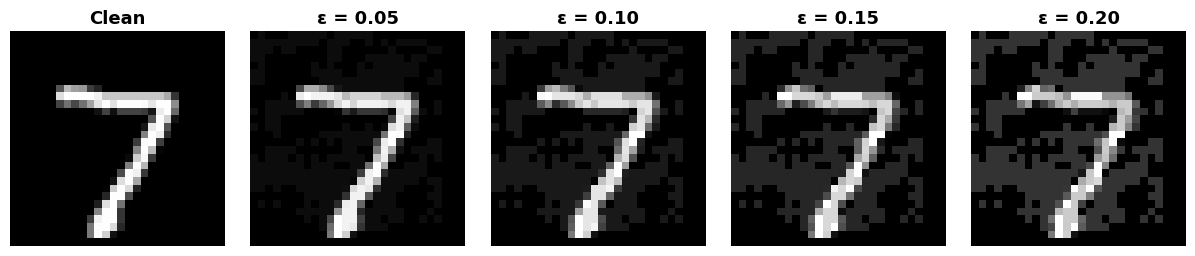

정답 레이블: 7
모델 A 예측: [7, 7, 7, 7, 7]
저장 완료: /content/drive/MyDrive/FGSM_Research/Main_Experiment/poster_figures/Figure5_FGSM_Examples.png


In [ ]:

import os
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

# 기존 모델 A 사용
model_A.eval()
device = next(model_A.parameters()).device

# MNIST 테스트 데이터
test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)

# Figure 1과 동일한 숫자 7 사용
idx = next(
    i for i, (_, label) in enumerate(test_dataset)
    if label == 7
)

image, label = test_dataset[idx]
x = image.unsqueeze(0).to(device)
y = torch.tensor([label], device=device)

epsilons = [0.00, 0.05, 0.10, 0.15, 0.20]

# 원본 이미지에서 입력 기울기 계산
x_input = x.clone().detach().requires_grad_(True)

model_A.zero_grad()
logits = model_A(x_input)
loss = F.cross_entropy(logits, y)
loss.backward()

gradient_sign = x_input.grad.detach().sign()

# 같은 이미지, 같은 기울기로 epsilon만 변경
images = []
predictions = []

for eps in epsilons:
    x_adv = torch.clamp(
        x + eps * gradient_sign,
        min=0.0,
        max=1.0
    )

    with torch.no_grad():
        pred = model_A(x_adv).argmax(dim=1).item()

    images.append(x_adv.cpu().squeeze().numpy())
    predictions.append(pred)

# 포스터용 Figure 5 생성
fig, axes = plt.subplots(1, 5, figsize=(12, 2.8))

for i, (ax, img, eps) in enumerate(
    zip(axes, images, epsilons)
):
    ax.imshow(
        img,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    title = "Clean" if eps == 0 else f"ε = {eps:.2f}"
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.axis("off")

plt.subplots_adjust(
    left=0.01,
    right=0.99,
    bottom=0.03,
    top=0.83,
    wspace=0.12
)

save_dir = (
    "/content/drive/MyDrive/FGSM_Research/"
    "Main_Experiment/poster_figures"
)
os.makedirs(save_dir, exist_ok=True)

save_path = f"{save_dir}/Figure5_FGSM_Examples.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.08,
    facecolor="white"
)

plt.show()
plt.close(fig)

print("정답 레이블:", label)
print("모델 A 예측:", predictions)
print("저장 완료:", save_path)


In [ ]:

import os
import matplotlib.pyplot as plt
from google.colab import files

# 기존 Figure 5 코드에서 생성한 images, epsilons 사용
save_dir = (
    "/content/drive/MyDrive/FGSM_Research/"
    "Main_Experiment/poster_figures/Figure5_Individual"
)
os.makedirs(save_dir, exist_ok=True)

saved_files = []

for eps, img in zip(epsilons, images):
    name = "Clean" if eps == 0 else f"eps_{eps:.2f}"
    path = f"{save_dir}/{name}.png"

    # 모두 동일한 28×28 정사각형 이미지
    plt.imsave(
        path,
        img,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    saved_files.append(path)
    print("저장 완료:", name)

# 5개 파일을 ZIP으로 묶어서 다운로드
import zipfile

zip_path = f"{save_dir}/Figure5_Images.zip"

with zipfile.ZipFile(zip_path, "w") as z:
    for path in saved_files:
        z.write(path, arcname=os.path.basename(path))

files.download(zip_path)


저장 완료: Clean
저장 완료: eps_0.05
저장 완료: eps_0.10
저장 완료: eps_0.15
저장 완료: eps_0.20


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>